# TP4 - Détection d’anomalie avec Python

**Étudiant :** Maxim Khomenko

**Numéro du TP :** 4

**Date :** 20 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** sys, numpy, pandas, warnings, scikit-learn, matplotlib, kagglehub, os

In [1]:
import sys
import numpy as np
np.set_printoptions(threshold=sys.maxsize) # np.nan est obsolète pour set_printoptions
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.ensemble import IsolationForest

In [2]:
# 2. Chargement
df_mouse = pd.read_csv("mouse.txt", header=None, sep=" ") # type: ignore

print("Structure (lignes, colonnes) :", df_mouse.shape)
print("\nStatistiques descriptives :\n", df_mouse.describe())

Structure (lignes, colonnes) : (500, 2)

Statistiques descriptives :
                 0           1
count  500.000000  500.000000
mean     0.505892    0.599706
std      0.191763    0.156863
min      0.040555    0.138940
25%      0.328481    0.469010
50%      0.504702    0.629494
75%      0.681430    0.735364
max      0.916030    0.897028


Le jeu de données contient 500 observations et 2 variables quantitatives, sans valeurs manquantes, avec des valeurs à la même échelle (entre 0,04 et 0,92, donc pas besoin de les standardiser). Ces chiffres seuls ne montrent pas d'anomalies évidentes, il faut donc afficher un graphique pour les repérer.

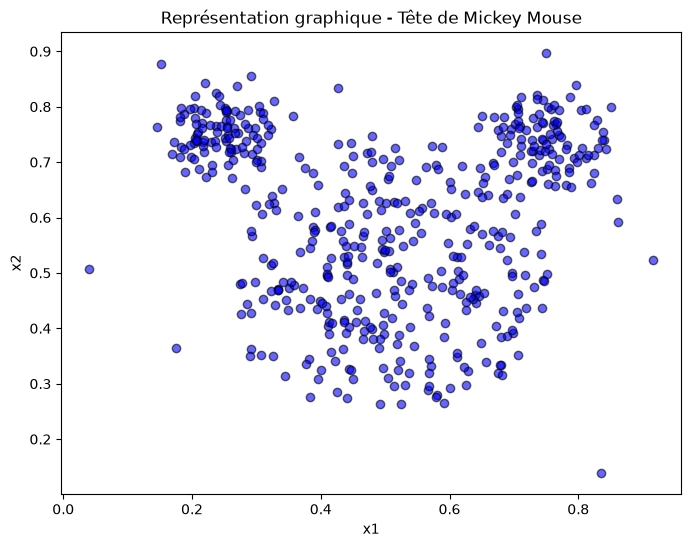

In [3]:
# 3. Représentation graphique des données
plt.figure(figsize=(8, 6))
plt.scatter(df_mouse[0], df_mouse[1], c='blue', alpha=0.6, edgecolors='k')
plt.title("Représentation graphique - Tête de Mickey Mouse")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [4]:
# 4. Application de la technique Isolation Forest
iso_mouse = IsolationForest(n_estimators=100, max_samples=256, contamination=0.02, random_state=0) # contamination = proportion attendue d'aberrants (10/500 = 0,02)

iso_mouse.fit(df_mouse)
pred_mouse = iso_mouse.predict(df_mouse)

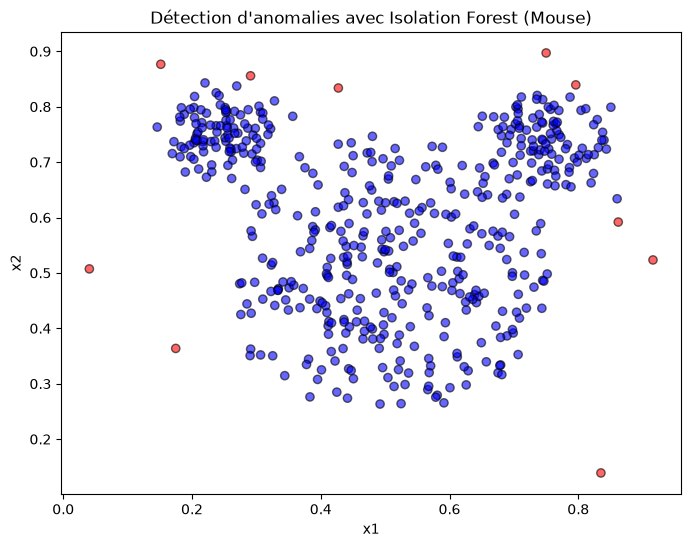

In [5]:
# 5. Visualisation des données aberrantes
plt.figure(figsize=(8, 6))
couleurs = ['blue' if x == 1 else 'red' for x in pred_mouse] # données normales (1) en bleu, anomalies (-1) en rouge

plt.scatter(df_mouse[0], df_mouse[1], c=couleurs, alpha=0.6, edgecolors='k')
plt.title("Détection d'anomalies avec Isolation Forest (Mouse)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

Le graphique montre qu'Isolation Forest signale 10 points, situés en dehors des zones denses qui forment la tête de Mickey. Comme ils sont isolés du reste du nuage, l'algorithme les sépare facilement en peu de coupures.

In [6]:
# 6. Chargement
import kagglehub
import os

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
csv_path = os.path.join(path, "creditcard.csv")

df_credit = pd.read_csv(csv_path) # type: ignore

df_normales = df_credit[df_credit['Class'] == 0].sample(n=5000, random_state=0)
df_fraudes = df_credit[df_credit['Class'] == 1]
df_echantillon = pd.concat([df_normales, df_fraudes])

X_credit = df_echantillon.drop(columns=['Class', 'Time'])
y_credit = df_echantillon['Class']

print("Taille de l'échantillon :", X_credit.shape)

Taille de l'échantillon : (5492, 29)


In [7]:
# 7. Application de la technique Isolation Forest
proportion_fraudes = len(df_fraudes) / len(df_echantillon) # proportion de fraudes dans l'échantillon

iso_credit = IsolationForest(n_estimators=100, max_samples=256, contamination=proportion_fraudes, random_state=0)
iso_credit.fit(X_credit)

pred_credit = (iso_credit.predict(X_credit) == -1).astype(int)

In [8]:
# 8. Matrice de confusion et analyse
from sklearn.metrics import confusion_matrix, classification_report

print("Matrice de confusion :")
print(confusion_matrix(y_credit, pred_credit))

print("\nRapport de classification :")
print(classification_report(y_credit, pred_credit, digits=3))

Matrice de confusion :
[[4855  145]
 [ 145  347]]

Rapport de classification :
              precision    recall  f1-score   support

           0      0.971     0.971     0.971      5000
           1      0.705     0.705     0.705       492

    accuracy                          0.947      5492
   macro avg      0.838     0.838     0.838      5492
weighted avg      0.947     0.947     0.947      5492



**Analyse des résultats (Credit Card)**

Les fraudes ne représentent que 0,172 % du jeu d’origine, on utilise donc un échantillon obtenu par sous-échantillonnage aléatoire de la classe majoritaire (5000 transactions normales + les 492 fraudes).

L'approche non supervisée Isolation Forest a été appliquée sans les variables Time et Class. La contamination a été fixée à la proportion de fraudes présente dans l'échantillon (environ 8,96 %). Les étiquettes ne sont pas utilisées pendant l'apprentissage, mais servent à déterminer cette proportion et à évaluer les résultats.

Matrice de confusion :
* Vrais négatifs (4855) : Transactions normales correctement identifiées.
* Vrais positifs (347) : Fraudes correctement détectées.
* Faux négatifs (145) : Fraudes non détectées.
* Faux positifs (145) : Transactions normales signalées à tort comme frauduleuses.

L’exactitude (0,947) est peu informative lorsque les classes sont déséquilibrées, donc l'évaluation se concentre sur le rappel (70,5 % des fraudes ont été détectées) et la précision (70,5 % des transactions signalées comme frauduleuses sont réellement des fraudes). Le F1-score est également de 70,5 %.